# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Михальчук Антон Євгенійович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 13      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 13, файл lr6_варіант_13.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль «відтік» має два значення (0/1) — передбачаємо клас, а не число

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: AUC не залежить від порогу — оцінює, чи ставить модель тих,
# хто піде, вище за тих, хто залишиться; точність і F1 залежать від обраного порогу

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація тримає 26,6 % відтоку в кожній згортці; 4 повтори дають
# 20 оцінок AUC, тож видно розкид і моделі можна порівнювати попарно на тих самих згортках

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.266

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
info = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False)
display(info)

,тип,унікальних,% пропусків,приклад
код_причини_закриття,str,5,73.4,ЯКІ-03
сума_повернення_депозиту,float64,317,73.4,272.05
середній_час_відповіді_хв,float64,273,33.2,14.4
трафік_ГБ,str,966,5.0,82.5
щомісячний_платіж,str,1128,4.0,329.8
аварій_на_ділянці_за_квартал,float64,5,3.0,0.0
стать,str,6,0.0,чол
місто,str,6,0.0,Львів
id_клієнта,str,1200,0.0,K130000
вік,float64,64,0.0,51.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
# 1–2) текстові колонки, де більшість значень — числа: що в них НЕ розбирається як число
for c in raw.columns:
    if pd.api.types.is_numeric_dtype(raw[c]):
        continue
    s = raw[c].dropna().astype(str)
    num = pd.to_numeric(s, errors='coerce')
    if num.notna().mean() > 0.8:
        bad = s[num.isna()]
        print('%-20s %3d з %d не число, напр.: %s' % (c, len(bad), len(s), bad.head(4).tolist()))

# 3) чи пропуски випадкові: частка відтоку там, де пропуск, і там, де значення є
print()
for c in raw.columns[raw.isna().any()]:
    na = raw[c].isna()
    print('%-30s пропусків %4d   відтік де пропуск %.2f, де є %.2f'
          % (c, na.sum(), raw.loc[na, TARGET].mean(), raw.loc[~na, TARGET].mean()))

# пропуски часу відповіді проти кількості звернень у підтримку
print()
print(raw.assign(пропуск=raw['середній_час_відповіді_хв'].isna())
         .groupby('кількість_звернень_у_підтримку')['пропуск'].agg(['mean', 'size'])
         .rename(columns={'mean': 'частка пропусків', 'size': 'клієнтів'}))

щомісячний_платіж     25 з 1152 не число, напр.: ['304.14 грн', '428.94 грн', '306.1 грн', '255.71 грн']
трафік_ГБ              3 з 1140 не число, напр.: ['1900-01-18 00:00:00', '1900-01-08 00:00:00', '1900-01-22 00:00:00']

щомісячний_платіж              пропусків   48   відтік де пропуск 0.19, де є 0.27
трафік_ГБ                      пропусків   60   відтік де пропуск 0.32, де є 0.26
аварій_на_ділянці_за_квартал   пропусків   36   відтік де пропуск 0.19, де є 0.27
середній_час_відповіді_хв      пропусків  398   відтік де пропуск 0.20, де є 0.30
сума_повернення_депозиту       пропусків  881   відтік де пропуск 0.00, де є 1.00
код_причини_закриття           пропусків  881   відтік де пропуск 0.00, де є 1.00

                                частка пропусків  клієнтів
кількість_звернень_у_підтримку                            
0                                            1.0       398
1                                            0.0       411
2                                            0

In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'          # 25 значень на кшталт '304.14 грн'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'                  # 3 значення на кшталт '1900-01-18' (= 18 ГБ)
PROBLEM_MNAR           = 'середній_час_відповіді_хв'  # 398 пропусків, усі — при 0 зверненнях
MNAR_MEANING           = 'клієнт ніколи не звертався в підтримку, тож часу відповіді не існує; заповнити медіаною — вигадати очікування, якого не було'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN            -> np.nan
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.date, pd.Timestamp)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if re.fullmatch(r'\d{4}-\d{2}-\d{2}( \d{2}:\d{2}(:\d{2})?)?', t):
            return np.nan                      # дата з Excel, записана текстом у CSV
        m = re.search(r'-?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['1900-01-18 00:00:00']))[0]), 'дата-текст теж брак'
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
SPELLING = {'стать': {'чол': 'ч', 'жін': 'ж'}}   # одна категорія, різне написання

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c == 'дата_підключення':                      # дата -> номер дня
            X[c] = (pd.to_datetime(s) - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            kind = 'дата -> дні від 2000-01-01'
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            kind = 'число'
        else:
            num = to_number(s)
            # «число» = значення ПОЧИНАЄТЬСЯ з числа ('329.8', '304.14 грн');
            # коди на кшталт 'КОД-028' чи 'Ф-01 Центр' — це категорії, не числа
            starts_num = s.dropna().astype(str).str.match(r'\s*-?\d')
            if starts_num.mean() > 0.8:
                X[c] = num
                kind = 'текст -> число'
            else:
                t = s.astype(str).str.strip().str.lower().where(s.notna())
                t = t.replace(SPELLING.get(c, {}))
                X[c] = t.astype('category')
                kind = 'категорія (%d рівнів)' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': kind, 'пропусків': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пропусків
0,вік,число,0
1,стать,категорія (2 рівнів),0
2,місто,категорія (6 рівнів),0
3,філія,категорія (6 рівнів),0
4,тариф,категорія (4 рівнів),0
5,тип_підключення,категорія (3 рівнів),0
6,спосіб_оплати,категорія (3 рівнів),0
7,автоплатіж,категорія (2 рівнів),0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.983


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.985 ± 0.009
час      : 0.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC 0.985 — модель майже завжди ставить того, хто піде, вище за того, хто лишиться; '
                  'для відтоку це нереально (>0.95), тож найімовірніше модель підглядає (витік), а не задача легка — '
                  'треба перевірити, які стовпці в неї йдуть')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.985 — модель майже завжди ставить того, хто піде, вище за того, хто лишиться; для відтоку це нереально (>0.95), тож найімовірніше модель підглядає (витік), а не задача легка — треба перевірити, які стовпці в неї йдуть


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_f, n_m = int(filled.sum()), int((~filled).sum())
        if n_f < min_group or n_m < min_group:      # одна з груп замала — показник шумовий
            continue
        auc = roc_auc_score(y, filled.astype(int))
        rows.append({'ознака': c, 'заповнено': n_f,
                     'частка_відтоку_де_заповнено': round(y[filled].mean(), 3),
                     'частка_відтоку_де_пропуск': round(y[~filled].mean(), 3),
                     'показник': round(max(auc, 1 - auc), 3)})   # напрям не важливий
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,сума_повернення_депозиту,319,1.000,0.000,1.000
5,код_причини_закриття,319,1.000,0.000,1.000
3,середній_час_відповіді_хв,802,0.300,0.196,0.559
0,щомісячний_платіж,1152,0.269,0.188,0.508
1,трафік_ГБ,1140,0.263,0.317,0.507
2,аварій_на_ділянці_за_квартал,1164,0.268,0.194,0.505


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають, коли договір уже розірвано — після результату
    'код_причини_закриття',       # причину закриття записують, коли рахунок уже закрито — після результату
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.923 ± 0.018


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # дзвонить відділ утримання — ПІСЛЯ того, як клієнт заявив, що хоче піти
]
HUMAN_LEAK_WHY = 'детектор дивиться лише на заповненість, а тут пропусків немає взагалі (0 дзвінків — це значення, не NaN), тож за заповненістю класи не розрізнити; витік у самому значенні і в тому, КОЛИ поле заповнюють'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.861 ± 0.022


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

                частка відтоку  клієнтів
філія                                   
Ф-01 Центр               0.400       215
Ф-02 Захід               0.439       205
Ф-03 Схід                0.177       186
Ф-04 Південь             0.190       184
Ф-05 Північ              0.179       201
Ф-06 Приміська           0.187       209

                  частка відтоку  клієнтів
дата_підключення                          
2023Q1                     0.303       152
2023Q2                     0.272       158
2023Q3                     0.220       141
2023Q4                     0.301       143
2024Q1                     0.305       141
2024Q2                     0.256       156
2024Q3                     0.224       165
2024Q4                     0.250       144


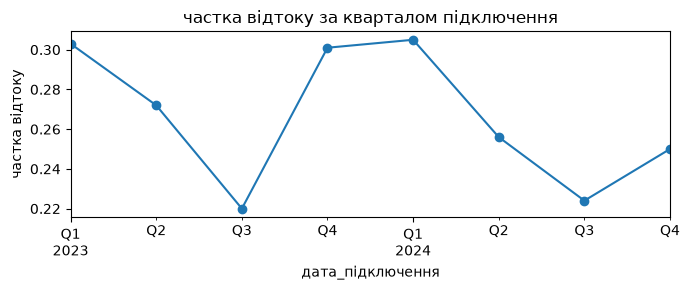

In [19]:
# 1) частка відтоку за філіями
print(raw.groupby('філія')[TARGET].agg(['mean', 'size'])
         .rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'}).round(3))
print()
# 2) частка відтоку по кварталах дати підключення — шукаємо сходинку
q = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
by_q = raw.groupby(q)[TARGET].agg(['mean', 'size']).rename(
    columns={'mean': 'частка відтоку', 'size': 'клієнтів'}).round(3)
print(by_q)
ax = by_q['частка відтоку'].plot(marker='o', figsize=(7, 3), title='частка відтоку за кварталом підключення')
ax.set_ylabel('частка відтоку'); plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# Ф-01 Центр і Ф-02 Захід: відтік 0.40–0.44 проти 0.18–0.19 в інших — сходинка, а не плавна зміна
SUSPECT_BRANCHES = ['Ф-01 Центр', 'Ф-02 Захід']
source = raw['філія'].astype(str).str.strip().isin(SUSPECT_BRANCHES).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.676
ті самі ознаки передбачають ВІДТІК  : AUC 0.825 ± 0.026


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.985
2. мінус цільовий витік,22,0.923
3. мінус оцінки людини,21,0.861
4. мінус артефакт збору,20,0.825


чесне число: 0.825 ± 0.026


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'залишити'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = ('відтік — це факт розірвання договору, записати його в різних філіях по-різному навряд чи можливо; '
                'вищий відтік у Центрі й на Заході, найімовірніше, справжній — там сильніші конкуренти')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

# Рішення «залишити» -> далі працюємо з набором, де філія є (X3), і чесне число — з нього.
# Сходинка 4 драбини (без філії) лишається в таблиці як чутливість: скільки AUC дає сама філія.
X_HONEST, auc_honest = (X3, auc3) if DECISION_ARTEFACT.startswith('залишити') else (X4, auc4)
HONEST_AUC = float(auc_honest.mean())
print('далі: %d ознак, чесне число %.3f ± %.3f' % (X_HONEST.shape[1], HONEST_AUC, auc_honest.std()))

залишити — відтік — це факт розірвання договору, записати його в різних філіях по-різному навряд чи можливо; вищий відтік у Центрі й на Заході, найімовірніше, справжній — там сильніші конкуренти
далі: 21 ознак, чесне число 0.861 ± 0.022


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                   random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                                           random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X_HONEST, clf), X_HONEST, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.861,0.022,0.8
одне дерево,0.776,0.029,0.6
випадковий ліс,0.863,0.021,9.7
гістограмний бустинг,0.873,0.017,10.7


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    # обидва масиви — на тих самих 20 згортках (cv має фіксований random_state),
    # тож різниця по згортці прибирає спільний шум «хто потрапив у згортку»
    d = np.asarray(b) - np.asarray(a)
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))


base = cross_val_score(make_pipe(X_HONEST, logreg()), X_HONEST, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X_HONEST, MODELS[name]), X_HONEST, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0023 ± 0.0090   у межах шуму


гістограмний бустинг   проти логістичної: +0.0119 ± 0.0092   значуще


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = ('якість: ліс проти неї +0.002 ± 0.009 (шум), бустинг +0.012 ± 0.009 — значуще, але мало; '
              'швидкість: 0.9 с проти 14.8 с у бустингу; інтерпретованість: коефіцієнти читаються напряму; '
              'стабільність: розкид ±0.022 як у лісу. Бракує їй лише нелінійних форм — це лікується ознакою '
              '(розділ 10.2б: з (вік−44)² вона дає 0.884, більше за бустинг)')
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)


обрано: логістична регресія — якість: ліс проти неї +0.002 ± 0.009 (шум), бустинг +0.012 ± 0.009 — значуще, але мало; швидкість: 0.9 с проти 14.8 с у бустингу; інтерпретованість: коефіцієнти читаються напряму; стабільність: розкид ±0.022 як у лісу. Бракує їй лише нелінійних форм — це лікується ознакою (розділ 10.2б: з (вік−44)² вона дає 0.884, більше за бустинг)


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # гіпотеза 1: клієнт, який платить багато за мегабіт, відчуває переплату і шукає дешевшого оператора
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза 2: важлива не кількість звернень, а їхня частота — 3 звернення за місяць гірше, ніж за 3 роки
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування'].clip(lower=1)
    # гіпотеза 3: користується мало, а платить — послуга не потрібна, легко відмовитись
    F['ГБ_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    # гіпотеза 4: аварія дратує сильніше, коли клієнт ще й звертався в підтримку (досвід поганого сервісу)
    F['аварії_x_звернення'] = F['аварій_на_ділянці_за_квартал'] * F['кількість_звернень_у_підтримку']
    return F


X5 = add_features(X_HONEST)
assert X5.shape[1] >= X_HONEST.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X_HONEST.shape[1], X5.shape[1]))

було 21 ознак, стало 25


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.860 ± 0.022
приріст проти базового набору: -0.0011 ± 0.0017   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = ('складніша модель дала більше, ніж мої чотири ознаки-відношення: бустинг +0.012 ± 0.009 (значуще) '
                     'ціною 14.8 с проти 0.9 с на 20 навчань, а ознаки −0.001 ± 0.002 (шум) практично безкоштовно — '
                     'вони лише перекомбінували інформацію, яку модель уже мала. Але ознака, побудована за формою з PDP '
                     '(розділ 10.2б, (вік−44)²), дала логістичній регресії +0.025 ± 0.005 — удвічі більше за бустинг '
                     'і без втрати швидкості: допомагає не будь-яка ознака, а та, що додає форму, якої модель не бачить')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)


складніша модель дала більше, ніж мої чотири ознаки-відношення: бустинг +0.012 ± 0.009 (значуще) ціною 14.8 с проти 0.9 с на 20 навчань, а ознаки −0.001 ± 0.002 (шум) практично безкоштовно — вони лише перекомбінували інформацію, яку модель уже мала. Але ознака, побудована за формою з PDP (розділ 10.2б, (вік−44)²), дала логістичній регресії +0.025 ± 0.005 — удвічі більше за бустинг і без втрати швидкості: допомагає не будь-яка ознака, а та, що додає форму, якої модель не бачить


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.856
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

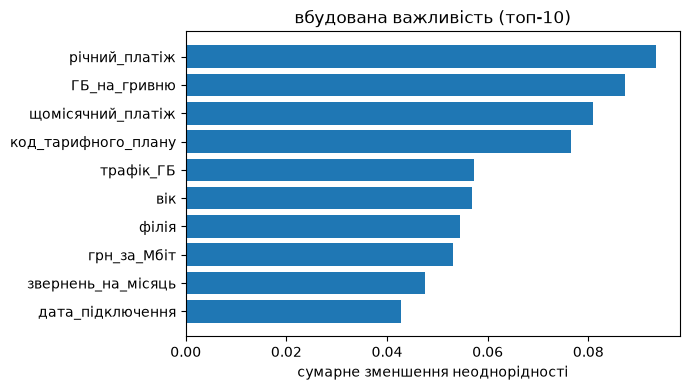

In [30]:
# 1) імена після перетворення: 'num__вік', 'cat__філія_Ф-01 Центр', ...
names = model.named_steps['prep'].get_feature_names_out()
raw_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)

# 2) дамі-стовпці однієї категоріальної ознаки підсумовуємо до вихідної ознаки
def base_name(n):
    kind, rest = n.split('__', 1)
    if kind == 'num':
        return rest
    return next(c for c in FINAL_X.columns if rest.startswith(c + '_'))

gini_imp = raw_imp.groupby([base_name(n) for n in raw_imp.index]).sum().sort_values(ascending=False)

# 3) топ-10
top = gini_imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(list(top.index), top.values)
ax.set_title('вбудована важливість (топ-10)'); ax.set_xlabel('сумарне зменшення неоднорідності')
plt.tight_layout(); plt.show()


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
ГБ_на_гривню,0.039869
філія,0.031491
річний_платіж,0.019531
вік,0.018590
аварії_x_звернення,0.010750
трафік_ГБ,0.008592
щомісячний_платіж,0.007659
місяців_обслуговування,0.007621
автоплатіж,0.005863
звернень_на_місяць,0.004806


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
imp_cmp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
imp_cmp['ранг вбудованої'] = range(1, len(imp_cmp) + 1)
imp_cmp['ранг перестановочної'] = imp_cmp['перестановочна'].rank(ascending=False).astype(int)
imp_cmp['унікальних значень'] = [FINAL_X[c].nunique() for c in imp_cmp.index]
display(imp_cmp.round(4).head(12))


,вбудована,перестановочна,ранг вбудованої,ранг перестановочної,унікальних значень
річний_платіж,0.0935,0.0195,1,3,1177
ГБ_на_гривню,0.0872,0.0399,2,1,1092
щомісячний_платіж,0.0809,0.0077,3,7,1128
код_тарифного_плану,0.0766,-0.0037,4,25,40
трафік_ГБ,0.0572,0.0086,5,6,963
вік,0.0568,0.0186,6,4,64
філія,0.0545,0.0315,7,2,6
грн_за_Мбіт,0.0531,0.0013,8,14,1146
звернень_на_місяць,0.0475,0.0048,9,10,147
дата_підключення,0.0428,-0.0025,10,22,609


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = ('4-та за вбудованою (0.077), але перестановочна −0.004 (25-те місце): '
                      'після одиничного кодування це 40 дамі-стовпців, і ліс у кожному дереві знаходить '
                      'серед них розбиття, що трохи зменшує неоднорідність на навчальних даних; підсумована '
                      'по 40 стовпцях дрібна «користь» дає велике число, хоча на перевірковій частині ознака нічого не дає')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)


хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename('r').reset_index())
pairs = pairs.reindex(pairs['r'].abs().sort_values(ascending=False).index)
display(pairs.head(6).round(3))


,level_0,level_1,r
78,щомісячний_платіж,річний_платіж,0.999
117,трафік_ГБ,ГБ_на_гривню,0.886
55,швидкість_тарифу_Мбіт,щомісячний_платіж,0.743
61,швидкість_тарифу_Мбіт,річний_платіж,0.742
64,швидкість_тарифу_Мбіт,грн_за_Мбіт,-0.656
152,аварій_на_ділянці_за_квартал,аварії_x_звернення,0.650


In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']   # r = 0.999: річний ≈ 12 × місячний        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

Xtr_1, Xte_1 = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])
model_1 = make_pipe(Xtr_1, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_1, ytr)
perm_1 = permutation_importance(model_1, Xte_1, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_1 = pd.Series(perm_1.importances_mean, index=Xte_1.columns)
print()
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (ранг %d з %d)' % (DUP_PAIR[0], perm_imp_1[DUP_PAIR[0]],
      perm_imp_1.rank(ascending=False)[DUP_PAIR[0]], len(perm_imp_1)))
print('   AUC моделі без пари: %.3f (повна: %.3f)'
      % (roc_auc_score(yte, model_1.predict_proba(Xte_1)[:, 1]), auc_hold))

у повній моделі:
   щомісячний_платіж            +0.0077
   річний_платіж                +0.0195



без річний_платіж:
   щомісячний_платіж            +0.0256   (ранг 3 з 24)
   AUC моделі без пари: 0.850 (повна: 0.856)


In [36]:
DUP_EXPLANATION = ('річний_платіж ≈ 12 × щомісячний_платіж (r = 0.999). У повній моделі перестановочна важливість '
                   'місячного лише +0.008: коли його перемішати, модель бере ту саму інформацію з річного. Без річного '
                   'важливість місячного зросла до +0.026 (3-тє місце), тобто приблизно до суми обох. Перестановочна '
                   'важливість відповідає на питання «що втратить модель без цієї ознаки», а з дублем вона не втрачає '
                   'нічого — тому висновок «важливість мала, отже ознаку можна викинути» хибний для пари разом')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)


річний_платіж ≈ 12 × щомісячний_платіж (r = 0.999). У повній моделі перестановочна важливість місячного лише +0.008: коли його перемішати, модель бере ту саму інформацію з річного. Без річного важливість місячного зросла до +0.026 (3-тє місце), тобто приблизно до суми обох. Перестановочна важливість відповідає на питання «що втратить модель без цієї ознаки», а з дублем вона не втрачає нічого — тому висновок «важливість мала, отже ознаку можна викинути» хибний для пари разом


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові: ['ГБ_на_гривню', 'річний_платіж', 'вік']


ГБ_на_гривню           сітка [0.14 0.33 0.52 0.71 0.9  1.1  1.29 1.48]
                       ризик [0.372 0.316 0.26  0.209 0.199 0.198 0.198 0.198]


річний_платіж          сітка [2349.7  2931.5  3513.31 4095.12 4676.92 5258.73 5840.53 6422.34]
                       ризик [0.227 0.224 0.231 0.272 0.31  0.355 0.379 0.396]


вік                    сітка [18.   24.37 30.74 37.11 43.48 49.85 56.22 62.59]
                       ризик [0.301 0.265 0.255 0.246 0.246 0.25  0.254 0.287]


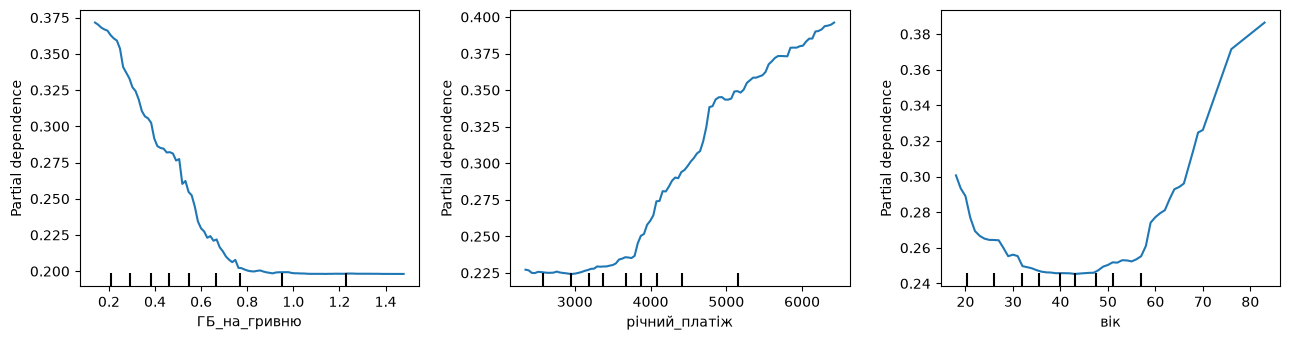

,розмах ризику,мін. у точці сітки,спочатку,наприкінці
ознака,,,,
ГБ_на_гривню,0.171,9,-1.0,-1.0
річний_платіж,0.164,1,1.0,1.0
щомісячний_платіж,0.137,2,1.0,1.0
звернень_на_місяць,0.097,0,1.0,1.0
швидкість_тарифу_Мбіт,0.088,1,1.0,1.0
трафік_ГБ,0.088,9,-1.0,-1.0
аварії_x_звернення,0.087,0,1.0,1.0
грн_за_Мбіт,0.067,5,-1.0,1.0
кількість_звернень_у_підтримку,0.063,0,1.0,1.0


In [37]:
from sklearn.inspection import PartialDependenceDisplay

num_feats = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
top3_num = [c for c in perm_imp.index if c in num_feats][:3]
print('три найважливіші числові:', top3_num)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for f, ax in zip(top3_num, axes):
    sub = Xte[Xte[f].notna()]                 # ознака з пропусками — лише там, де вона заповнена
    PartialDependenceDisplay.from_estimator(model, sub, [f], kind='average', ax=ax)
    pd_res = partial_dependence(model, sub, [f], kind='average', grid_resolution=8)
    print('%-22s сітка %s' % (f, np.round(pd_res['grid_values'][0], 2)))
    print('%-22s ризик %s' % ('', np.round(pd_res['average'][0], 3)))
plt.tight_layout(); plt.show()

# пошук немонотонних: для кожної числової ознаки — скільки разів крива змінює напрям
shape_rows = []
for f in num_feats:
    sub = FINAL_X[FINAL_X[f].notna()]
    r = partial_dependence(model, sub, [f], kind='average', grid_resolution=10)['average'][0]
    dif = np.diff(r)
    shape_rows.append({'ознака': f, 'розмах ризику': r.max() - r.min(),
                       'мін. у точці сітки': int(np.argmin(r)),
                       'спочатку': np.sign(dif[:3].sum()), 'наприкінці': np.sign(dif[-3:].sum())})
shape = pd.DataFrame(shape_rows).set_index('ознака').sort_values('розмах ризику', ascending=False)
display(shape.round(3))

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

          частка відтоку  клієнтів
вік                               
(17, 25]           0.344       209
(25, 32]           0.283       173
(32, 40]           0.227       238
(40, 48]           0.192       250
(48, 56]           0.232       185
(56, 70]           0.320       128


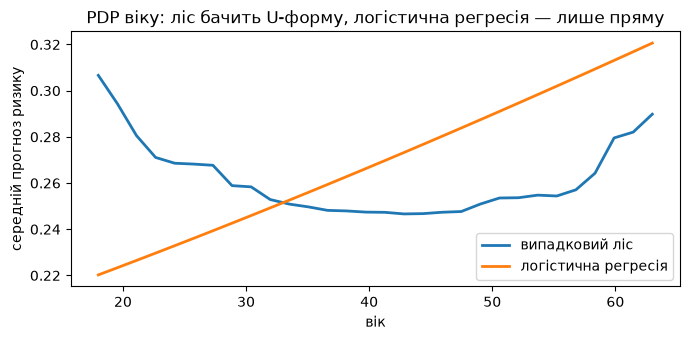

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# емпірична перевірка по сирих даних: частка відтоку за віковими групами
age_bins = pd.cut(FINAL_X['вік'], [17, 25, 32, 40, 48, 56, 70])
print(y.groupby(age_bins, observed=True).agg(['mean', 'size']).rename(
    columns={'mean': 'частка відтоку', 'size': 'клієнтів'}).round(3))

# один рисунок, дві криві — ліс і логістична регресія на тій самій ознаці
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(7, 3.5))
for m_, lbl in [(model, 'випадковий ліс'), (model_lr, 'логістична регресія')]:
    r = partial_dependence(m_, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=30)
    ax.plot(r['grid_values'][0], r['average'][0], label=lbl, lw=2)
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз ризику'); ax.legend()
ax.set_title('PDP віку: ліс бачить U-форму, логістична регресія — лише пряму')
plt.tight_layout(); plt.show()


In [39]:
NONLINEAR_MEANING = ('ризик U-подібний за віком: найвищий у молодих (18–25 р., відтік 34 %) і старших (56+, 32 %), '
                     'найнижчий у 40–48 р. (19 %) — молоді легко перемикаються на дешевші пропозиції, '
                     'старші частіше відмовляються від послуги взагалі; середній вік — найстабільніші клієнти')
NONLINEAR_FIX = ('ознака «квадрат відхилення від віку мінімального ризику» (вік − 44)²: '
                 'вона зростає в обидва боки, тож лінійна модель може дати їй один додатний коефіцієнт')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)


ризик U-подібний за віком: найвищий у молодих (18–25 р., відтік 34 %) і старших (56+, 32 %), найнижчий у 40–48 р. (19 %) — молоді легко перемикаються на дешевші пропозиції, старші частіше відмовляються від послуги взагалі; середній вік — найстабільніші клієнти
ознака «квадрат відхилення від віку мінімального ризику» (вік − 44)²: вона зростає в обидва боки, тож лінійна модель може дати їй один додатний коефіцієнт


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# 1) з PDP і сирої таблиці: мінімум ризику в групі 40–48 років -> беремо 44
AGE_MIN_RISK = 44
# 2) ознака «квадрат відхилення від цього значення»
X_quad = FINAL_X.assign(вік_відхилення_кв=(FINAL_X['вік'] - AGE_MIN_RISK) ** 2)
# 3) парне порівняння логістичної регресії з нею і без неї — ті самі 20 згорток
auc_lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_quad = cross_val_score(make_pipe(X_quad, logreg()), X_quad, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lr_base, auc_lr_quad)
print('логістична без ознаки : AUC %.3f ± %.3f' % (auc_lr_base.mean(), auc_lr_base.std()))
print('логістична з ознакою  : AUC %.3f ± %.3f' % (auc_lr_quad.mean(), auc_lr_quad.std()))
print('приріст: %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))


логістична без ознаки : AUC 0.860 ± 0.022
логістична з ознакою  : AUC 0.884 ± 0.015
приріст: +0.0248 ± 0.0052   значуще


In [41]:
QUAD_GAIN = float(m_q)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)


приріст від сконструйованої ознаки: +0.0248


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

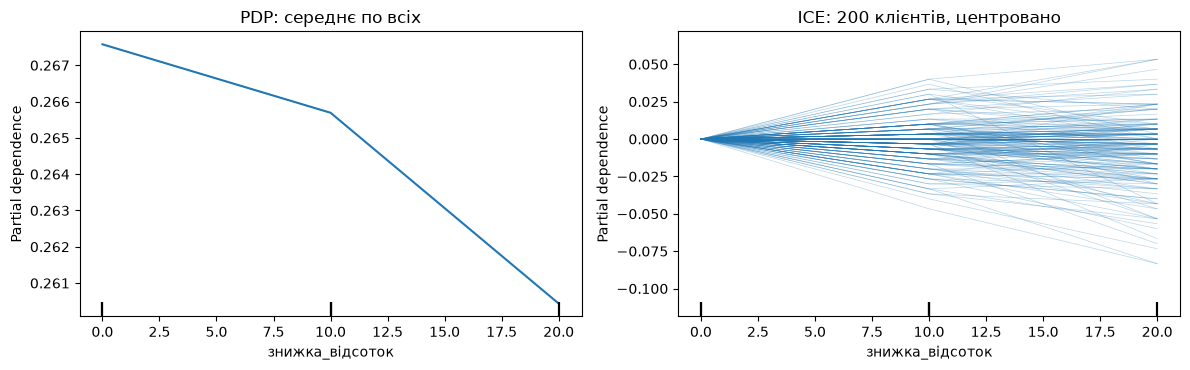

сітка знижки: [ 0. 10. 20.]
PDP (середнє): [0.268 0.266 0.26 ]
ICE: у 49 % клієнтів знижка знижує ризик, у 24 % — підвищує


In [42]:
# 1) звичайний PDP по всій вибірці і 2) ICE — крива на кожного клієнта (центровані, щоб бачити напрям)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=axes[0])
axes[0].set_title('PDP: середнє по всіх')
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual',
                                        centered=True, subsample=200, random_state=SEED, ax=axes[1])
axes[1].set_title('ICE: 200 клієнтів, центровано')
plt.tight_layout(); plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')
eff = ice['individual'][0][:, -1] - ice['individual'][0][:, 0]     # ефект найбільшої знижки проти нульової
avg = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
print('сітка знижки:', ice['grid_values'][0])
print('PDP (середнє):', np.round(avg['average'][0], 3))
print('ICE: у %.0f %% клієнтів знижка знижує ризик, у %.0f %% — підвищує'
      % (100 * (eff < -0.005).mean(), 100 * (eff > 0.005).mean()))


стаж ≤ 24 міс  [0.299 0.3   0.297]


стаж > 24 міс  [0.216 0.21  0.201]


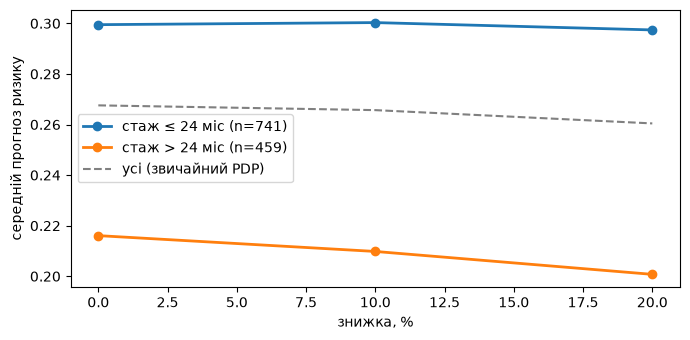

In [43]:
mask_new = FINAL_X['місяців_обслуговування'] <= 24
fig, ax = plt.subplots(figsize=(7, 3.5))
for mask, lbl in [(mask_new, 'стаж ≤ 24 міс'), (~mask_new, 'стаж > 24 міс')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2, label='%s (n=%d)' % (lbl, mask.sum()))
    print('%-14s %s' % (lbl, np.round(r['average'][0], 3)))
r_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ax.plot(r_all['grid_values'][0], r_all['average'][0], ls='--', color='grey', label='усі (звичайний PDP)')
ax.set_xlabel('знижка, %'); ax.set_ylabel('середній прогноз ризику'); ax.legend()
plt.tight_layout(); plt.show()


### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
tenure_grp = np.where(FINAL_X['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24')
emp = (pd.DataFrame({'знижка': FINAL_X['знижка_відсоток'], 'стаж': tenure_grp, 'відтік': y})
         .pivot_table(index='знижка', columns='стаж', values='відтік', aggfunc=['mean', 'size']))
emp.columns = ['відтік: ' + b if a == 'mean' else 'n: ' + b for a, b in emp.columns]
display(emp.round(3))


,відтік: стаж > 24,відтік: стаж ≤ 24,n: стаж > 24,n: стаж ≤ 24
знижка,,,,
0.0,0.246,0.260,187,285
10.0,0.199,0.363,146,273
20.0,0.032,0.366,126,183


In [45]:
INTERACTION_FOUND = ('звичайний PDP знижки майже плаский (0.268 → 0.260), але ICE показує різні напрями '
                     '(у 49 % клієнтів знижка знижує ризик, у 24 % — підвищує). У сирих даних: при стажі > 24 міс '
                     'відтік падає зі знижкою 24.6 % → 19.9 % → 3.2 % (0/10/20 %), а при стажі ≤ 24 міс зростає '
                     '26.0 % → 36.3 % → 36.6 %. Протилежні ефекти погасили один одного в середньому. Ліс відтворює '
                     'цю картину лише слабко (PDP по підгрупах майже пласкі) — тож тут питання вже до моделі, не до PDP')
BUSINESS_ACTION = ('знижку пропонувати клієнтам зі стажем понад 2 роки — там вона утримує; новим клієнтам знижка '
                   'не допомагає (вони йдуть так само або частіше — схоже на мисливців за акціями), '
                   'для них потрібен інший засіб утримання')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)


звичайний PDP знижки майже плаский (0.268 → 0.260), але ICE показує різні напрями (у 49 % клієнтів знижка знижує ризик, у 24 % — підвищує). У сирих даних: при стажі > 24 міс відтік падає зі знижкою 24.6 % → 19.9 % → 3.2 % (0/10/20 %), а при стажі ≤ 24 міс зростає 26.0 % → 36.3 % → 36.6 %. Протилежні ефекти погасили один одного в середньому. Ліс відтворює цю картину лише слабко (PDP по підгрупах майже пласкі) — тож тут питання вже до моделі, не до PDP
знижку пропонувати клієнтам зі стажем понад 2 роки — там вона утримує; новим клієнтам знижка не допомагає (вони йдуть так само або частіше — схоже на мисливців за акціями), для них потрібен інший засіб утримання


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 83)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

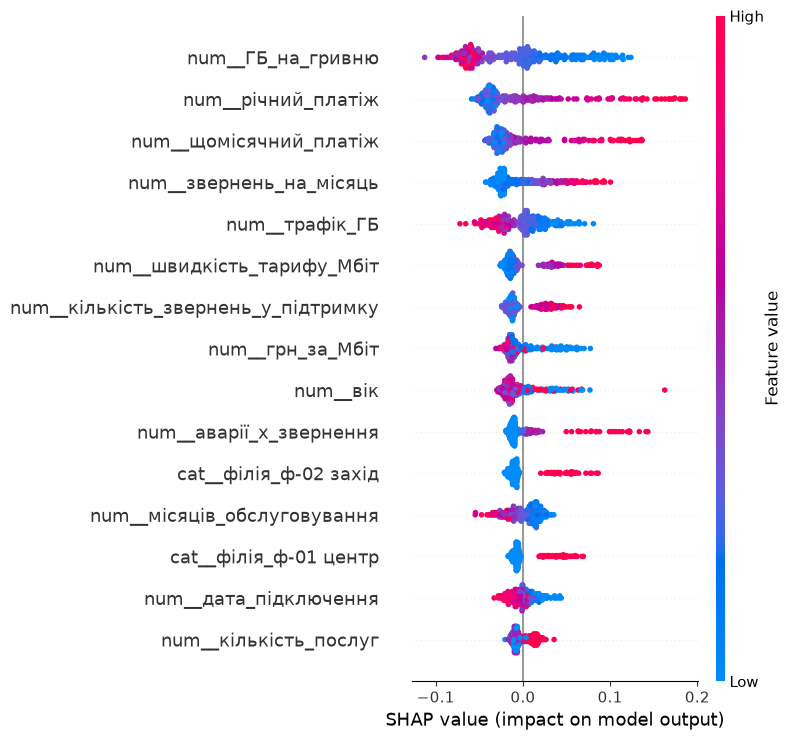

,середній |внесок|,напрям (r значення-внесок)
num__ГБ_на_гривню,0.047,-0.804
num__річний_платіж,0.043,0.934
num__щомісячний_платіж,0.032,0.894
num__звернень_на_місяць,0.027,0.905
num__трафік_ГБ,0.021,-0.859
num__швидкість_тарифу_Мбіт,0.021,0.942
num__кількість_звернень_у_підтримку,0.019,0.889
num__грн_за_Мбіт,0.019,-0.468
num__вік,0.018,-0.176
num__аварії_x_звернення,0.017,0.916


In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=15, show=False)
plt.tight_layout(); plt.show()

# числом: середній |внесок| і кореляція «значення ознаки -> внесок» (знак = напрям дії)
sv_df = pd.DataFrame(sv1, columns=feat_names)
val_df = pd.DataFrame(Xte_t[:SAMPLE], columns=feat_names)
shap_tab = pd.DataFrame({'середній |внесок|': sv_df.abs().mean(),
                         'напрям (r значення-внесок)': [np.corrcoef(val_df[c], sv_df[c])[0, 1]
                                                        if val_df[c].std() > 0 else np.nan for c in feat_names]})
display(shap_tab.sort_values('середній |внесок|', ascending=False).head(10).round(3))


### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
raw_row = Xte.iloc[idx]
print('базовий рівень (середній прогноз): %.3f' % np.ravel(expl.expected_value)[-1])
for n, v in top3.items():
    base = n.split('__', 1)[1]
    col = next((c for c in FINAL_X.columns if base == c or base.startswith(c + '_')), base)
    print('  %-40s внесок %+.3f   значення клієнта: %s' % (n, v, raw_row[col]))
print('сума всіх внесків + база = %.3f' % (contrib.sum() + np.ravel(expl.expected_value)[-1]))

ризик клієнта: 0.870
базовий рівень (середній прогноз): 0.266
  num__річний_платіж                       внесок +0.151   значення клієнта: 7204.1
  num__щомісячний_платіж                   внесок +0.113   значення клієнта: 599.14
  num__ГБ_на_гривню                        внесок +0.100   значення клієнта: 0.205961878692793
сума всіх внесків + база = 0.870


In [49]:
EXPLANATION_FOR_MANAGER = ('Ризик відходу цього клієнта — 87 % при середньому 27 %. Головна причина — ціна: він платить '
                           'близько 600 грн на місяць (понад 7 200 грн на рік), це один із найдорожчих рахунків. Друга — '
                           'він мало користується інтернетом: близько 0,2 ГБ на кожну сплачену гривню, тобто платить багато '
                           'за те, чого майже не використовує. Розмову варто почати з дешевшого тарифу, який відповідає '
                           'його реальному споживанню.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)


Ризик відходу цього клієнта — 87 % при середньому 27 %. Головна причина — ціна: він платить близько 600 грн на місяць (понад 7 200 грн на рік), це один із найдорожчих рахунків. Друга — він мало користується інтернетом: близько 0,2 ГБ на кожну сплачену гривню, тобто платить багато за те, чого майже не використовує. Розмову варто почати з дешевшого тарифу, який відповідає його реальному споживанню.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'ГБ_на_гривню'
SHAP_NOT_CAUSAL_WHY = ('найбільший середній внесок за Шеплі (0.047; мало ГБ на гривню -> вищий ризик), але це наслідок, '
                       'а не причина: клієнт мало качає, бо послуга йому мало потрібна. Якщо «підняти» ознаку, '
                       'подарувавши трафік, потреба не зміниться і клієнт так само піде. Модель цією ознакою '
                       'користується як симптомом; щоб казати «змінимо — лишиться», потрібен експеримент '
                       '(частині клієнтів дати пропозицію, частині — ні), а не значення Шеплі')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)


ГБ_на_гривню — найбільший середній внесок за Шеплі (0.047; мало ГБ на гривню -> вищий ризик), але це наслідок, а не причина: клієнт мало качає, бо послуга йому мало потрібна. Якщо «підняти» ознаку, подарувавши трафік, потреба не зміниться і клієнт так само піде. Модель цією ознакою користується як симптомом; щоб казати «змінимо — лишиться», потрібен експеримент (частині клієнтів дати пропозицію, частині — ні), а не значення Шеплі


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",ГБ_на_гривню,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = ('філія — 2-га за перестановочною важливістю (+0.031), і пояснення «клієнти Центру й Заходу ризикові» '
                 'звучить природно. Але в розділі 6 решта ознак вгадує філію з AUC 0.676, а відтік у Ф-01/Ф-02 '
                 'стрибком удвічі вищий (40–44 % проти 18–19 %). Дані не розрізняють «там справді сильніша конкуренція» '
                 'і «там інакше збирали/записували дані». Я залишив філію, але читати її внесок як властивість клієнтів '
                 'не можна, і в новій філії модель може помилятись. Схожа пастка в 11.3: два з трьох головних внесків '
                 'для найризиковішого клієнта — це одна й та сама інформація (місячний і річний платіж), '
                 'Шеплі довільно ділить її між дублями')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)


філія — 2-га за перестановочною важливістю (+0.031), і пояснення «клієнти Центру й Заходу ризикові» звучить природно. Але в розділі 6 решта ознак вгадує філію з AUC 0.676, а відтік у Ф-01/Ф-02 стрибком удвічі вищий (40–44 % проти 18–19 %). Дані не розрізняють «там справді сильніша конкуренція» і «там інакше збирали/записували дані». Я залишив філію, але читати її внесок як властивість клієнтів не можна, і в новій філії модель може помилятись. Схожа пастка в 11.3: два з трьох головних внесків для найризиковішого клієнта — це одна й та сама інформація (місячний і річний платіж), Шеплі довільно ділить її між дублями


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]
order = np.argsort(-risk)
hits = int(yte.iloc[order[:TOP_N]].sum())
base_rate = yte.mean()
lift = (hits / TOP_N) / base_rate
print('у перевірковій частині %d клієнтів, пішли %.1f %%' % (len(yte), 100 * base_rate))
print('топ-%d за ризиком: пішли %d (%.0f %%)' % (TOP_N, hits, 100 * hits / TOP_N))
print('навмання 100: очікувано %.0f' % (TOP_N * base_rate))
print('lift = %.2f' % lift)


у перевірковій частині 360 клієнтів, пішли 26.7 %
топ-100 за ризиком: пішли 62 (62 %)
навмання 100: очікувано 27
lift = 2.33


In [54]:
LIFT_MEANING = ('lift 2.33: обдзвонюючи 100 клієнтів зі списку моделі, відділ утримання знайде 62 тих, хто справді '
                'збирається піти, замість ~27 при виборі навмання — у 2,3 раза більше за ті самі зусилля')
assert LIFT_MEANING
print(LIFT_MEANING)


lift 2.33: обдзвонюючи 100 клієнтів зі списку моделі, відділ утримання знайде 62 тих, хто справді збирається піти, замість ~27 при виборі навмання — у 2,3 раза більше за ті самі зусилля


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_13.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Метрика — AUC. Відтік у моїх даних 26,6 % (319 з 1200), тож модель «ніхто не піде» має точність 73,4 %,
   нічого не вміючи. AUC не залежить від порогу: це частка пар «пішов / лишився», де модель поставила того,
   хто пішов, вище; випадкова модель дає 0,5. Схема — стратифікована 5-кратна з 4 повторами (20 оцінок).

2. Викинуті стовпці:
   - id_клієнта — ідентифікатор, нічого не пояснює;
   - сума_повернення_депозиту — з'являється після розірвання договору, коли повертають депозит;
   - код_причини_закриття — записується після закриття рахунку;
   - кількість_дзвінків_утримання — заповнює відділ утримання ПІСЛЯ того, як клієнт заявив про намір піти
     (серед тих, кому дзвонили, пішли 72 %, серед решти — 6 %).
   Детектор із 5.1 знайшов перші два (заповнені рівно в 319 клієнтів, що пішли; показник 1,0). Дзвінки
   утримання він не знайшов: пропусків там немає (0 дзвінків — це значення), а детектор дивиться лише
   на заповненість. Витік — у змісті поля і в тому, коли його заповнюють.
   Драбина AUC: 0,985 → 0,923 → 0,861 → 0,825 (останній крок — без філії, див. п. 4).

3. Чесне число — AUC 0,861 ± 0,022 (логістична регресія, 21 ознака, з філією). Розкид між згортками
   0,022 — це коливання лише від того, які клієнти потрапили в згортку, у п'ять разів більше
   за 0,004. Тому різниця 0,004 між двома моделями за середніми нічого не означає; порівнювати треба
   парно на тих самих згортках: середня різниця ± 1,96·std/√20. Наприклад, ліс проти логістичної
   +0,002 ± 0,009 — у межах шуму.

4. Артефакт збору — підозра є. Відтік у Ф-01 Центр і Ф-02 Захід 40–44 %, в інших чотирьох 18–19 % —
   сходинка, а не плавна зміна (по кварталах підключення лише коливання 22–31 %). Чесні ознаки
   передбачають «клієнт із Ф-01/Ф-02» з AUC 0,676 — у даних закодоване джерело. Я вирішив філію
   залишити: відтік — факт розірвання договору, записати його по-різному в різних філіях важко,
   а вищий відтік, найімовірніше, справжній (сильніша конкуренція). Без філії AUC 0,825. У новій
   філії модель довіри не заслуговує без перевірки: вона частково вивчила «яка це філія».

5. Складніша модель дала більше, ніж мої чотири ознаки-відношення: гістограмний бустинг
   +0,012 ± 0,009 (значуще) ціною 14,8 с проти 0,9 с на 20 навчань; ознаки (грн за Мбіт, звернень
   на місяць, ГБ на гривню, аварії × звернення) — −0,001 ± 0,002, у межах шуму. Але ознака,
   побудована за формою з PDP, (вік − 44)², дала логістичній регресії +0,025 ± 0,005 (0,860 → 0,884)
   без втрати швидкості — більше, ніж бустинг. Тому обрав логістичну регресію.

6. Вбудована важливість переоцінила код_тарифного_плану: 4-те місце (0,077), а перестановочна −0,004
   (25-те з 25). Після одиничного кодування це 40 дамі-стовпців; дерево перебирає їх як кандидатів
   на розбиття і майже завжди знаходить таке, що трохи зменшує неоднорідність на навчальних даних.
   Вбудована важливість рахується на навчальній вибірці і підсумовує ці дрібні «виграші».

7. Дубльована пара — щомісячний_платіж і річний_платіж (r = 0,999, річний ≈ 12 × місячний).
   У повній моделі перестановочна важливість місячного +0,008, річного +0,020; після вилучення
   річного місячний виріс до +0,026 (3-тє місце). Перемішування однієї ознаки пари нічого не ламає —
   модель бере ту саму інформацію з другої. Метод відповідає точно на своє питання («що втратить
   модель без цієї ознаки»); помилка — читати малу важливість як «ознаку можна викинути».

8. Немонотонний вплив має вік: ризик U-подібний. У сирих даних відтік 34 % у 18–25 р., 19 % у 40–48 р.,
   32 % у 56+. Логістична регресія може провести лише пряму (ризик тільки росте або тільки спадає з віком), ліс — U-форму.
   Без мого втручання лінійна модель цього не побачить за побудовою; з ознакою (вік − 44)² — бачить
   (+0,025 AUC, значуще).

9. PDP знижки майже плаский (ризик 0,268 → 0,260 при знижці 0 → 20 %), ніби знижка не діє. ICE
   показав різні напрями: у 49 % клієнтів знижка знижує ризик, у 24 % — підвищує. По сирих даних:
   стаж > 24 міс — відтік 24,6 % → 19,9 % → 3,2 %; стаж ≤ 24 міс — 26,0 % → 36,3 % → 36,6 %.
   Ефекти протилежні й у середньому погасились. Ліс відтворює взаємодію лише слабко — це вже
   обмеження моделі. Висновок для бізнесу: знижку давати довготривалим клієнтам, новим — ні.

10. ГБ_на_гривню — найбільший середній внесок за Шеплі (0,047). Але це симптом: клієнт мало качає,
    бо послуга йому мало потрібна. Подарований трафік змінить ознаку, але не потребу — клієнт піде
    однаково. «Модель цим користується» означає, що ознака допомагає вгадувати; «це причина» означає,
    що зміна ознаки змінить результат — це перевіряє лише експеримент (частині клієнтів дати
    пропозицію, частині — ні), а не значення Шеплі.

11. Замовнику: 100 клієнтів із найвищим ризиком у перевірковій частині (360 осіб) містять 62 тих,
    хто справді пішов, проти ~27 при виборі навмання — lift 2,33. Застереження: це одне відкладене
    розбиття з 360 клієнтів, тож число шумне; і модель каже, ХТО піде, а не КОГО вдасться втримати
    дзвінком чи знижкою (див. п. 9: новим клієнтам знижка не допомагає).

Декларація про використання ШІ:
Користувався ШІ-асистентом Claude (Anthropic). Він пояснив теорію лабораторної (окрема сторінка з
поясненнями на моїх даних), написав програмний код комірок і чернетки текстових відповідей розділів
7–15. Рішення розділів 1–6 (тип задачі, метрика, схема перевірки, проблемні стовпці, сенс пропусків,
цільовий витік і поле, яке заповнює людина, рішення залишити філію) я ухвалював сам у діалозі з
асистентом, який ставив навідні питання. Відповіді розділів 7–15 я перечитав і звірив з числами
в ноутбуці.
'''
print(REPORT)



1. Метрика — AUC. Відтік у моїх даних 26,6 % (319 з 1200), тож модель «ніхто не піде» має точність 73,4 %,
   нічого не вміючи. AUC не залежить від порогу: це частка пар «пішов / лишився», де модель поставила того,
   хто пішов, вище; випадкова модель дає 0,5. Схема — стратифікована 5-кратна з 4 повторами (20 оцінок).

2. Викинуті стовпці:
   - id_клієнта — ідентифікатор, нічого не пояснює;
   - сума_повернення_депозиту — з'являється після розірвання договору, коли повертають депозит;
   - код_причини_закриття — записується після закриття рахунку;
   - кількість_дзвінків_утримання — заповнює відділ утримання ПІСЛЯ того, як клієнт заявив про намір піти
     (серед тих, кому дзвонили, пішли 72 %, серед решти — 6 %).
   Детектор із 5.1 знайшов перші два (заповнені рівно в 319 клієнтів, що пішли; показник 1,0). Дзвінки
   утримання він не знайшов: пропусків там немає (0 дзвінків — це значення), а детектор дивиться лише
   на заповненість. Витік — у змісті поля і в тому, коли його заповнюю

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.